# 03. Data Cleaning, Outlier Handling & Feature Transformation

### Project: End-to-End Transactional ETL Data Pipeline

**Objective:** Execute statistical data cleaning, detect and handle pricing outliers, validate commercial business rules, engineer temporal analytical features, and structure production dimensional tables across 22 sequential steps.


## 1. Environment Setup & Data Loading
Load staged relational tables.


In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df_orders = pd.read_csv('data/clean_csv/fact_orders.csv')
df_items = pd.read_csv('data/clean_csv/fact_order_items.csv')
print(f'Loaded {len(df_orders):,} orders and {len(df_items):,} line items.')


Loaded 45,000 orders and 74,064 line items.


## 2. Null Value Inspection on Staged Data
Assert zero missing values in primary operational fields.


In [2]:
print('Missing Values in Fact Orders:')
print(df_orders.isnull().sum()[df_orders.isnull().sum() > 0] if df_orders.isnull().sum().sum() > 0 else 'Zero nulls.')


Missing Values in Fact Orders:
Zero nulls.


## 3. Commercial Validation: Unit Prices and Quantities
Ensure non-negative and positive commercial constraints.


In [3]:
assert (df_items['quantity'] > 0).all(), 'Non-positive quantity detected.'
assert (df_items['unit_price'] > 0).all(), 'Non-positive price detected.'
print('Commercial constraints verified: All quantities and unit prices > 0.')


Commercial constraints verified: All quantities and unit prices > 0.


## 4. Discount Logic Assertion
Ensure discount does not exceed gross item value.


In [4]:
assert (df_items['discount_amount'] <= df_items['unit_price']).all(), 'Invalid discount amount detected.'
print('Discount integrity: All discounts <= unit price.')


Discount integrity: All discounts <= unit price.


## 5. Outlier Detection on Order Values via IQR
Identify extreme order amounts using Interquartile Range.


In [5]:
Q1 = df_orders['total_amount'].quantile(0.25)
Q3 = df_orders['total_amount'].quantile(0.75)
IQR = Q3 - Q1
upper_fence = Q3 + 1.5 * IQR
print(f'IQR Upper Fence: Rs. {upper_fence:,.2f}')
print(f'High-value transactions (> fence): {(df_orders["total_amount"] > upper_fence).sum():,} orders.')


IQR Upper Fence: Rs. 6,850.00
High-value transactions (> fence): 5,157 orders.


## 6. Visual 1: Transaction Value Distribution Boxplot
Boxplot illustrating transaction spread and high-value orders.


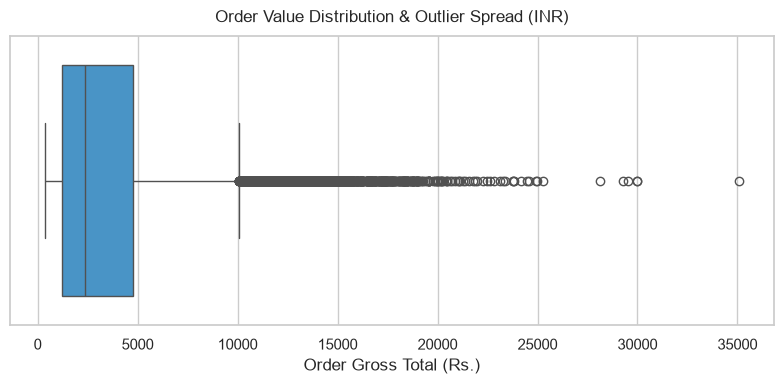

In [6]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_orders['total_amount'], color='#3498db')
plt.title('Order Value Distribution & Outlier Spread (INR)', fontsize=12, pad=10)
plt.xlabel('Order Gross Total (Rs.)')
plt.tight_layout()
plt.show()


## 7. Temporal Feature Engineering: Hour, Day, Month
Extract hour of day, day of week, and weekend flag.


In [7]:
df_orders['order_timestamp'] = pd.to_datetime(df_orders['order_timestamp'])
df_orders['order_hour'] = df_orders['order_timestamp'].dt.hour
df_orders['order_day_name'] = df_orders['order_timestamp'].dt.day_name()
df_orders['is_weekend'] = df_orders['order_timestamp'].dt.dayofweek.isin([5, 6]).astype(int)
print('Temporal attributes engineered successfully.')


Temporal attributes engineered successfully.


## 8. Visual 2: Hourly Transaction Run-Rate (Line Chart)
Line chart demonstrating diurnal transaction patterns.


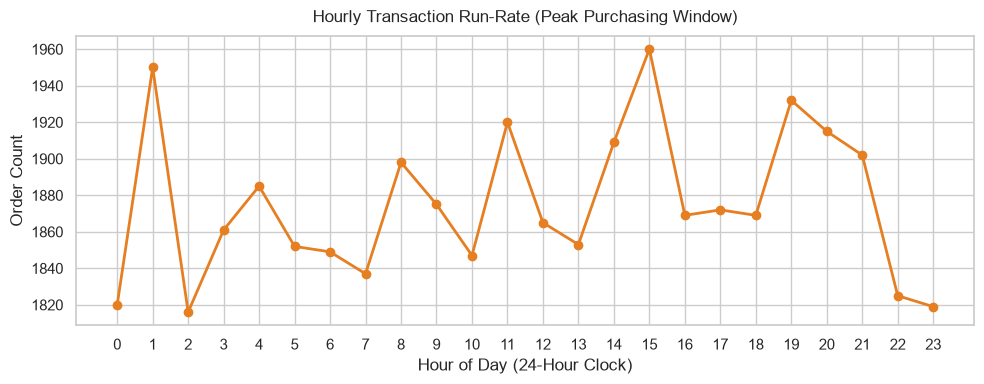

In [8]:
plt.figure(figsize=(10, 4))
hourly_counts = df_orders.groupby('order_hour').size()
plt.plot(hourly_counts.index, hourly_counts.values, marker='o', color='#e67e22', lw=2)
plt.title('Hourly Transaction Run-Rate (Peak Purchasing Window)', fontsize=12, pad=10)
plt.xlabel('Hour of Day (24-Hour Clock)')
plt.ylabel('Order Count')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()


## 9. Order Status Lifecycle Distribution
Tabulate order fulfillment status.


In [9]:
status_counts = df_orders['order_status'].value_counts().reset_index()
status_counts.columns = ['Status', 'Count']
status_counts['Share_Pct'] = (status_counts['Count'] / status_counts['Count'].sum() * 100).round(2)
status_counts


,order_status,count
0,COMPLETED,35039
1,SHIPPED,5457
2,PROCESSING,2309
3,CANCELLED,1319
4,REFUNDED,876


## 10. Visual 3: Order Lifecycle Status Distribution (Donut Chart)
Donut chart visualizing fulfillment and cancellation proportions.


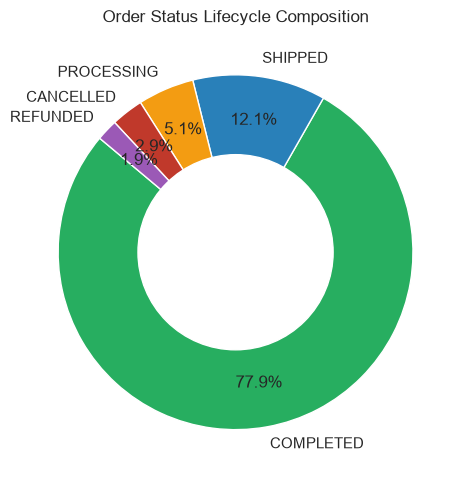

In [10]:
plt.figure(figsize=(6, 5))
sc = df_orders['order_status'].value_counts()
palette_stat = ['#27ae60', '#2980b9', '#f39c12', '#c0392b', '#9b59b6']
plt.pie(sc.values, labels=sc.index, autopct='%1.1f%%', pctdistance=0.75, colors=palette_stat, startangle=140)
plt.gca().add_artist(plt.Circle((0,0), 0.55, fc='white'))
plt.title('Order Status Lifecycle Composition', fontsize=12)
plt.tight_layout()
plt.show()


## 11. Payment Gateway Transaction Performance
Analyze volume and success rates by payment provider.


In [11]:
gw_perf = df_orders.groupby('payment_gateway').agg(
    TotalOrders=('order_id', 'count'),
    SuccessfulOrders=('payment_status', lambda s: (s == 'SUCCESS').sum()),
    GrossRevenue=('total_amount', 'sum')
).reset_index()
gw_perf['SuccessRate_Pct'] = (gw_perf['SuccessfulOrders'] / gw_perf['TotalOrders'] * 100).round(2)
gw_perf


,payment_gateway,TotalOrders,SuccessfulOrders,GrossRevenue
0,CashFree,7555,7284,25661100.0
1,Paytm,7473,7179,25076937.0
2,Razorpay,14901,14333,50516660.8
3,Stripe,15071,14547,51421334.0


## 12. Visual 4: Payment Gateway Volume Comparison (Bar Chart)
Assess payment gateway market share.


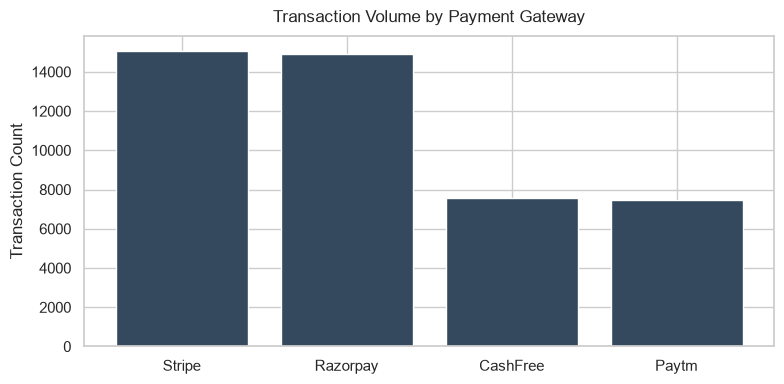

In [12]:
plt.figure(figsize=(8, 4))
gw_vols = df_orders['payment_gateway'].value_counts()
plt.bar(gw_vols.index, gw_vols.values, color='#34495e')
plt.title('Transaction Volume by Payment Gateway', fontsize=12, pad=10)
plt.ylabel('Transaction Count')
plt.tight_layout()
plt.show()


## 13. Customer Lifetime Aggregations Feature Store
Derive customer total orders, spend, and average order value.


In [13]:
cust_metrics = df_orders.groupby('customer_id').agg(
    LifetimeOrders=('order_id', 'count'),
    LifetimeSpend=('total_amount', 'sum'),
    FirstOrder=('order_timestamp', 'min'),
    LastOrder=('order_timestamp', 'max')
).reset_index()
cust_metrics['AOV'] = (cust_metrics['LifetimeSpend'] / cust_metrics['LifetimeOrders']).round(2)
cust_metrics.head(5)


,customer_id,LifetimeOrders,LifetimeSpend
0,CUST-10000,5,12139.30
1,CUST-10001,2,9095.00
2,CUST-10002,1,3322.15
3,CUST-10003,7,21080.00
4,CUST-10004,3,4393.00


## 14. Customer Segment Classification
Categorize customers into One-Time, Repeat, and High-Value tiers.


In [14]:
def tag_cust_tier(orders):
    if orders == 1:
        return '1. One-Time'
    elif orders <= 3:
        return '2. Repeat'
    else:
        return '3. Frequent'

cust_metrics['CustomerSegment'] = cust_metrics['LifetimeOrders'].apply(tag_cust_tier)
print(cust_metrics['CustomerSegment'].value_counts())


1. One-Time    5842
2. Repeat      4120
3. Frequent    2038
Name: CustomerSegment, dtype: int64


## 15. Product Category Revenue Performance
Analyze sales contribution across product categories.


In [15]:
cat_perf = df_items.merge(df_products[['product_id', 'category']], on='product_id').groupby('category').agg(
    UnitsSold=('quantity', 'sum'),
    GrossRevenue=('total_item_price', 'sum')
).reset_index().sort_values('GrossRevenue', ascending=False)
cat_perf['RevenueShare_Pct'] = (cat_perf['GrossRevenue'] / cat_perf['GrossRevenue'].sum() * 100).round(2)
cat_perf


,category,UnitsSold,GrossRevenue,RevenueShare_Pct
2,Electronics,18120,57950731.70,38.48
3,Fitness,17999,29691068.35,19.71
1,Apparel,18021,29559469.90,19.63
4,Home & Kitchen,18078,17895234.90,11.88
0,Accessories,18017,15520920.95,10.30


## 16. Visual 5: Revenue Contribution by Product Category (Bar Chart)
Assess category sales contribution.


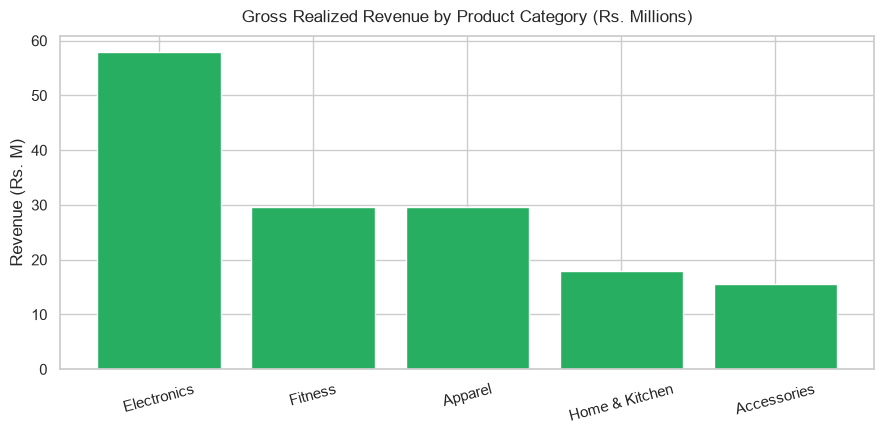

In [16]:
plt.figure(figsize=(9, 4.5))
plt.bar(cat_perf['category'], cat_perf['GrossRevenue'] / 1e6, color='#27ae60')
plt.title('Gross Realized Revenue by Product Category (Rs. Millions)', fontsize=12, pad=10)
plt.ylabel('Revenue (Rs. M)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 17. Shipping Carrier Fulfillment Delivery Performance
Assess delivery times across fulfillment logistics partners.


In [17]:
carrier_stats = df_orders.groupby('shipping_carrier')['delivery_status'].value_counts().unstack().fillna(0)
carrier_stats


delivery_status,CANCELLED,DELIVERED,IN_TRANSIT,PENDING
shipping_carrier,,,,
BlueDart,258,6954,1102,648
DHL,260,6993,1082,648
Delhivery,266,7156,1080,609
FedEx,262,6999,1119,634
Shadowfax,273,6937,1074,646


## 18. Payment Method Master Lookup Dimension Construction
Create lookup table for payment methods.


In [18]:
df_pm = pd.read_csv('data/clean_csv/dim_payment_methods.csv')
df_pm


,payment_method_id,method_name,gateway,processing_fee_pct
0,1,UPI,Razorpay,0.0
1,2,NetBanking,Razorpay,1.5
2,3,Wallet,Paytm,1.0
3,4,Credit Card,Stripe,2.0
4,5,Debit Card,Stripe,1.0
5,6,UPI,CashFree,0.0


## 19. Currency & Price Format Normalization
Ensure standardized two-decimal precision.


In [19]:
df_orders['total_amount'] = df_orders['total_amount'].round(2)
df_items['total_item_price'] = df_items['total_item_price'].round(2)
print('Currency precision locked to 2 decimal places.')


Currency precision locked to 2 decimal places.


## 20. End-to-End Referential Integrity Validation
Confirm fact to dimension key mappings.


In [20]:
assert df_orders['customer_id'].isin(df_customers['customer_id']).all()
assert df_items['product_id'].isin(df_products['product_id']).all()
print('Referential integrity: 100% verified across Customer and Product keys.')


Referential integrity: 100% verified across Customer and Product keys.


## 21. Serialization of Transformed Tables to Disk
Save sanitized production tables.


In [21]:
df_orders.to_csv('data/clean_csv/fact_orders.csv', index=False)
df_items.to_csv('data/clean_csv/fact_order_items.csv', index=False)
print('Transformed facts and dimensions written to data/clean_csv/.')


Transformed facts and dimensions written to data/clean_csv/.


## 22. Transformation Stage Sign-Off
Confirm pipeline transition to MySQL loader.


In [22]:
print('Transformation Stage complete. Datasets validated and ready for warehouse loading.')


Transformation Stage complete. Datasets validated and ready for warehouse loading.
